# Proyecto 4: Integración Numérica y Cálculo de Áreas Irregulares

En este notebook realizamos el análisis estocástico y de escalabilidad de alto rendimiento (HPC) sobre los datos recolectados mediante el Método de Monte Carlo paralelizado con MPI.

### Especificaciones del Entorno y Telemetría de Hardware
Para garantizar la reproducibilidad científica y contextualizar las métricas de rendimiento frente a la microarquitectura real de ejecución, las características del hardware y software fueron extraídas y documentadas en dos archivos de telemetría:
1. **`specs_entorno.txt`:** Telemetría de la PC Local (AMD Ryzen 5 3450U, 4 núcleos / 8 hilos, 8 GB RAM).
2. **`specs_entorno_servidor.txt`:** Telemetría del Servidor HPC (Dual AMD EPYC 7B12, 128 núcleos físicos, 512 GB RAM).

Comando de extracción ejecutado en el sistema:
```bash
! (echo "--- CPU ---"; lscpu; echo -e "\n--- RAM ---"; free -h; echo -e "\n--- OS ---"; cat /etc/os-release; echo -e "\n--- MPI ---"; mpicc --version) > specs_entorno.txt
```


--- 
## 1. Configuración y Carga de Datos
Definimos qué figura vamos a analizar. En nuestro proyecto estudiaremos círculo y parábola.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import os

sns.set_theme(style="whitegrid", context="talk")

# ==========================================
# PARÁMETROS DEL EXPERIMENTO
# ==========================================
# Cambia esto a 'circulo' o 'parabola' según los CSVs que desees analizar
FIGURA = 'circulo'
ENTORNO = 'servidor'

# Detección inteligente de archivos (soporta tanto _pc.csv como _resultados.csv)
ARCHIVO_INTEGRAL = f'integral_{FIGURA}_{ENTORNO}.csv'
ARCHIVO_AREA = f'area_{FIGURA}_{ENTORNO}.csv'

if FIGURA == 'circulo':
    VALOR_TEORICO = np.pi
elif FIGURA == 'parabola':
    VALOR_TEORICO = 1.0 / 3.0
else:
    VALOR_TEORICO = 1.0 # Fallback
    
print(f"Analizando geometría: {FIGURA.upper()} | Valor Analítico Esperado: {VALOR_TEORICO}")
print(f"Archivos cargados: {ARCHIVO_INTEGRAL} | {ARCHIVO_AREA}")

# Paleta fija para las gráficas de las secciones 4.2, 5 y 6.1
FONDO, TINTA_2 = 'white', '#52514e'
METODOS  = ['Integral 1D', 'Área 2D']
ENTORNOS = ['PC', 'Servidor']
COLOR_METODO  = {'Integral 1D': '#2a78d6', 'Área 2D': '#eb6834'}
COLOR_ENTORNO = {'PC': '#6250d6', 'Servidor': '#1baf7a'}
CMAP_SEQ = mcolors.LinearSegmentedColormap.from_list(
    'azul', ['#f4f8fd', '#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])

def etiqueta_N(n):
    return f'$10^{{{int(round(np.log10(n)))}}}$'

Analizando geometría: CIRCULO | Valor Analítico Esperado: 3.141592653589793
Archivos cargados: integral_circulo_servidor.csv | area_circulo_servidor.csv


--- 
## 2. Procesamiento de los datos
En este bloque:
 - Creamos los dataframes para manejar los datos de los csv
 - Calculamos las medianas de los tiempos y los valores recolectados.
 - Calculamos speedup, eficiencia y error absoluto

In [2]:
try:
    df_integral = pd.read_csv(ARCHIVO_INTEGRAL)
    df_area = pd.read_csv(ARCHIVO_AREA)

    # Agrupamos por N y procesos,
    # calculando la mediana de los tiempos y estimaciones
    med_integral = df_integral.groupby(['N', 'procesos'])[['tiempo_segundos', 'valor_estimado']].median().reset_index()
    med_area = df_area.groupby(['N', 'procesos'])[['tiempo_segundos', 'valor_estimado']].median().reset_index()

    med_integral['Método'] = 'Integral 1D'
    med_area['Método'] = 'Área 2D'

    df_resultados = pd.concat([med_integral, med_area])
    
    # Cálculo de métricas avanzadas
    #tiempo de 1 proceso
    df_t1 = df_resultados[df_resultados['procesos'] == 1].set_index(['Método', 'N'])['tiempo_segundos']
    df_resultados['T1'] = df_resultados.set_index(['Método', 'N']).index.map(df_t1)
    #speedup: t1/ttotal
    df_resultados['Speedup'] = df_resultados['T1'] / df_resultados['tiempo_segundos']
    #eficiencia: speedup/nro de procesos
    df_resultados['Eficiencia'] = df_resultados['Speedup'] / df_resultados['procesos']
    #error absoluto: |valor estimado - valor teórico|
    df_resultados['Error Absoluto'] = abs(df_resultados['valor_estimado'] - VALOR_TEORICO)
    
    # Convertimos N a variable categórica (texto) para que Seaborn asigne colores distintos y claros
    df_resultados['N_cat'] = df_resultados['N'].apply(
        lambda x: f"10^{int(np.log10(x))}"
    )
    
    display(df_resultados.head())
except FileNotFoundError:
    print("⚠️ Advertencia: Aún no se han encontrado los archivos CSV. Ejecuta los scripts en bash primero.")

,N,procesos,tiempo_segundos,valor_estimado,Método,T1,Speedup,Eficiencia,Error Absoluto,N_cat
0,10000,1,0.000141,3.132264,Integral 1D,0.000141,1.000000,1.000000,0.009329,10^4
1,10000,2,0.000078,3.136463,Integral 1D,0.000141,1.807692,0.903846,0.005130,10^4
2,10000,4,0.000056,3.140621,Integral 1D,0.000141,2.517857,0.629464,0.000972,10^4
3,10000,8,0.000039,3.128885,Integral 1D,0.000141,3.615385,0.451923,0.012708,10^4
4,10000,16,0.000034,3.134844,Integral 1D,0.000141,4.147059,0.259191,0.006749,10^4


---
## 3. Error vs N
Analizamos la convergencia del error con 1 proceso en un gráfico log-log. La teoría de Monte Carlo predice que el error decrece como $\sigma/\sqrt{N}$, donde $\sigma$ es la desviación estándar de una sola muestra del estimador: en escala log-log eso es una recta de pendiente $-1/2$ (multiplicar $N$ por 100 divide el error por 10).

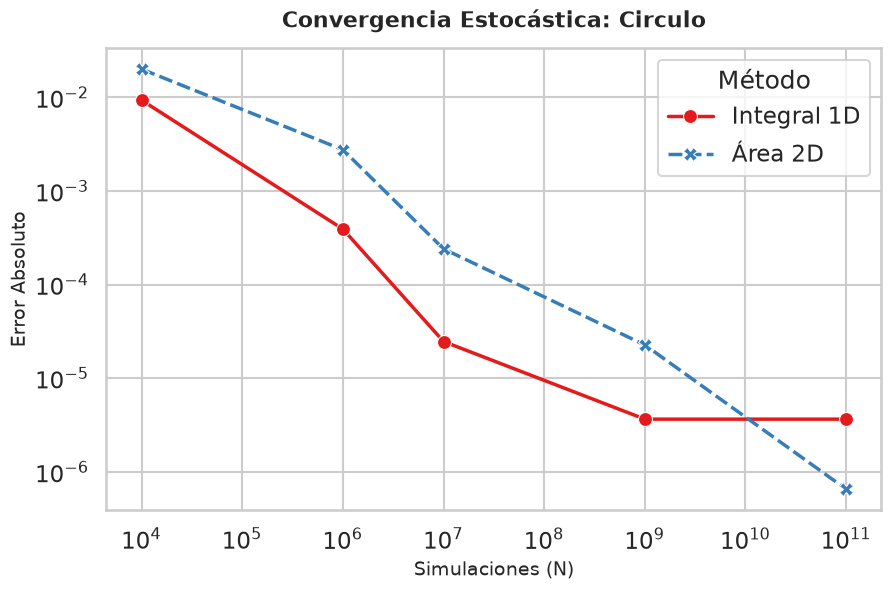

In [3]:
plt.figure(figsize=(10, 6))
if 'df_resultados' in locals():
    # Graficamos la convergencia para la corrida base (1 proceso)
    df_convergencia = df_resultados[df_resultados['procesos'] == 1]
    
    sns.lineplot(data=df_convergencia, x='N', y='Error Absoluto', hue='Método', markers=True, style='Método', palette='Set1', linewidth=2.5, markersize=10)
    
    plt.title(f'Convergencia Estocástica: {FIGURA.capitalize()}', fontsize=16, fontweight='bold', pad=15)
    plt.xlabel('Simulaciones (N)', fontsize=14)
    plt.ylabel('Error Absoluto', fontsize=14)
    plt.xscale('log')
    plt.yscale('log') 
    plt.legend(title='Método')
    plt.show()

> 🧠 **Análisis:**
> - **La tendencia sigue la ley $1/\sqrt{N}$.** De $N=10^4$ a $N=10^{11}$ ($N$ crece 7 órdenes de magnitud) el error baja entre 3.4 y 4.5 órdenes de magnitud, cerca de los 3.5 que predice la teoría.
> - **La curva no es una recta perfecta** porque cada punto es **una única estimación**: con 1 proceso y semilla fija, las 5 repeticiones dan el mismo valor, así que no hay promedio. El error de una corrida fluctúa alrededor de $\sigma/\sqrt{N}$; por ejemplo, en la Integral 1D el error con $N=10^9$ y con $N=10^{11}$ es prácticamente el mismo ($3.7\cdot10^{-6}$). Además, el valor se imprime con 6 decimales, así que no se pueden medir errores menores a $\sim 5\cdot10^{-7}$.
> - **La Integral 1D tiene menos error que el Área 2D** en todos los $N$ salvo $10^{11}$: su desviación por muestra es menor ($\sigma \approx 0.89$ frente a $1.64$), porque cada muestra aporta un valor continuo y no solo un acierto o un fallo.

---
## 4. Speedup en el Servidor
### 4.1 Speedup vs número de procesos
El speedup $S(p) = T_1/T_p$ indica cuántas veces más rápido corre el programa con $p$ procesos que con 1. La línea punteada es el caso ideal $S = p$.

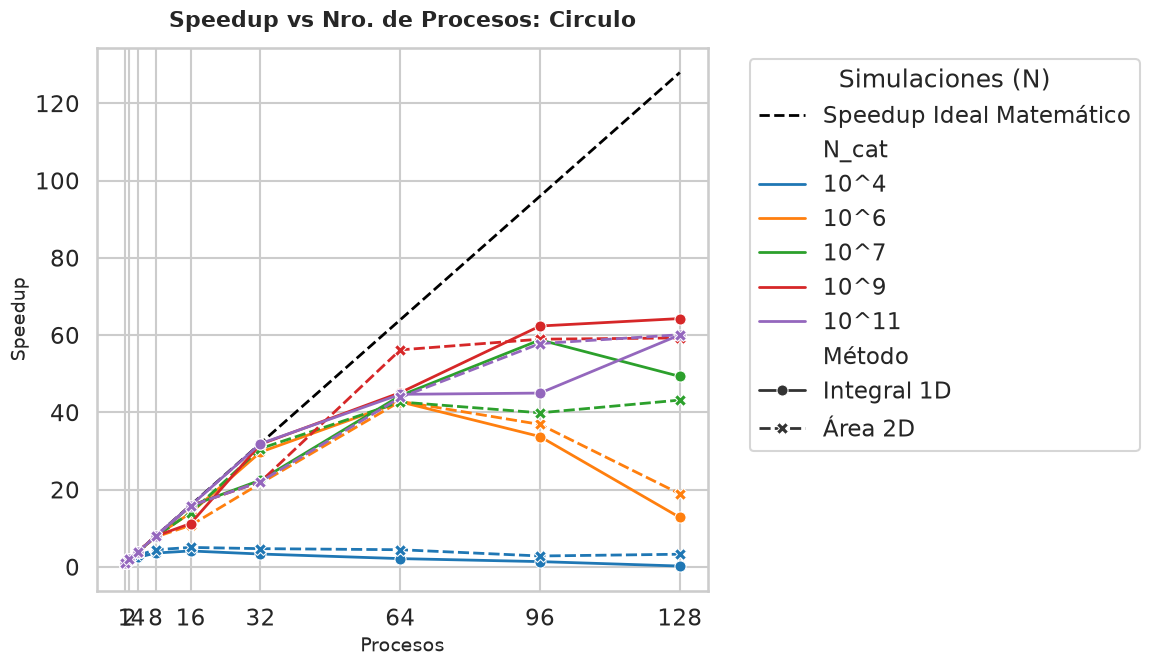

In [4]:
plt.figure(figsize=(12, 7))
if 'df_resultados' in locals():
    max_p = df_resultados['procesos'].max()
    plt.plot([1, max_p], [1, max_p], color='black', linestyle='--', linewidth=2, label='Speedup Ideal Matemático')
    
    sns.lineplot(data=df_resultados, x='procesos', y='Speedup', hue=df_resultados['N_cat'], style='Método', markers=True, palette='tab10', linewidth=2, markersize=8)
    
    plt.title(f'Speedup vs Nro. de Procesos: {FIGURA.capitalize()}', fontsize=16, fontweight='bold', pad=15)
    plt.xlabel('Procesos', fontsize=14)
    plt.ylabel('Speedup', fontsize=14)
    plt.xticks(df_resultados['procesos'].unique())
    plt.legend(title='Simulaciones (N)', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

> 🧠 **Análisis:**
> - **Con $N \ge 10^7$ y hasta 8 procesos, las curvas se superponen a la diagonal** (eficiencia ≈ 0.98–1.00). Monte Carlo es *embarrassingly parallel*: cada proceso genera sus muestras de forma independiente y se comunica una sola vez al final (`MPI_Reduce` de un `double`).
> - **Desde 16–32 procesos las curvas se separan del ideal.** Con 128 procesos el speedup llega a $S \approx 43$–$64$ (≈ 60 para $N \ge 10^9$). Esa distancia no se explica por la comunicación: un único `MPI_Reduce` de 8 bytes cuesta microsegundos, frente a segundos o minutos de cálculo. Se explica porque cada núcleo procesa más lento cuando hay muchos activos (bajada de frecuencia y competencia con otros procesos del servidor; ver sección 5).
> - **Con $N = 10^6$ el speedup tiene un máximo en 64 procesos (≈ 43×) y después baja**: con 128 procesos cada uno procesa solo ≈ 8 000 muestras, y el costo fijo de arrancar y sincronizar pesa más que el cálculo.
> - **Con $N = 10^4$ no conviene paralelizar.** El cálculo serial dura ~0.1–0.2 ms, el speedup no supera ≈ 4–5× y, en la Integral 1D con 128 procesos, el programa es **4 veces más lento que el serial** ($S = 0.25$).

### 4.2 ¿Con cuántos procesos conviene correr cada N?
Para cada $N$ se busca el número de procesos que da el mayor speedup. Más procesos no siempre es mejor: si el problema es chico, el costo fijo de MPI supera la ganancia.

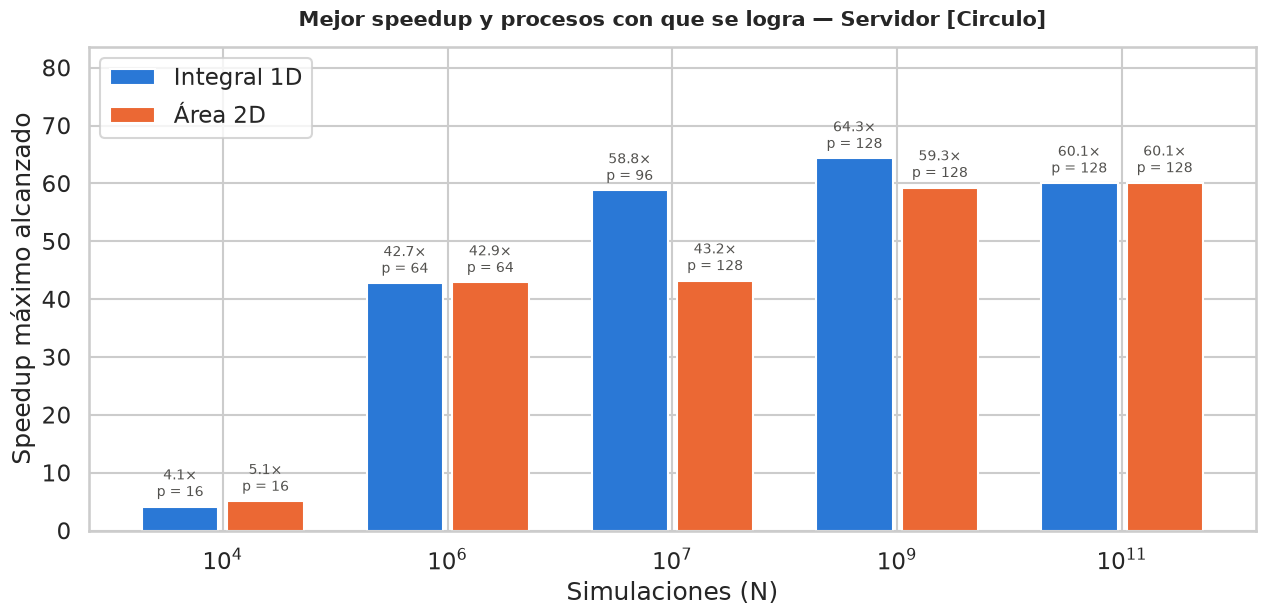

In [5]:
if 'df_resultados' in locals():
    srv = df_resultados.reset_index(drop=True)   # índice único, necesario para idxmax
    best = srv.loc[srv.groupby(['Método', 'N'])['Speedup'].idxmax()]
    N_vals = sorted(srv['N'].unique())

    fig, ax = plt.subplots(figsize=(13, 6.5))
    ancho = 0.38
    for j, metodo in enumerate(METODOS):
        b = best[best['Método'] == metodo].sort_values('N')
        x = np.arange(len(b)) + (j - 0.5) * ancho
        ax.bar(x, b['Speedup'], width=ancho - 0.04, color=COLOR_METODO[metodo], label=metodo)
        for xi, sp, p in zip(x, b['Speedup'], b['procesos']):
            ax.text(xi, sp + 1, f'{sp:.1f}×\np = {p}', ha='center', va='bottom', fontsize=10, color=TINTA_2)
    ax.set_xticks(np.arange(len(N_vals)), [etiqueta_N(n) for n in N_vals])
    ax.set(xlabel='Simulaciones (N)', ylabel='Speedup máximo alcanzado', ylim=(0, best['Speedup'].max() * 1.3))
    ax.set_title(f'Mejor speedup y procesos con que se logra — {ENTORNO.capitalize()} [{FIGURA.capitalize()}]',
                 fontsize=15, fontweight='bold', pad=15)
    ax.legend(loc='upper left')
    plt.tight_layout()
    plt.show()

> 🧠 **Análisis:**
> - **Altura de cada barra:** el mejor speedup que se logró para ese $N$. **Etiqueta $p$:** con cuántos procesos se logró.
> - **La cantidad óptima de procesos crece con el tamaño del problema:** 16 procesos para $N=10^4$, 64 para $N=10^6$, y 96–128 desde $N=10^7$.
> - Es la **ley de Amdahl** en *strong scaling* ($N$ fijo): el costo fijo (arrancar los procesos, sincronizar, reducir) no se divide entre procesos, así que solo se compensa si cada proceso tiene suficiente trabajo.
> - Los dos métodos alcanzan speedups máximos parecidos (≈ 60× para $N \ge 10^9$) porque **se paralelizan de la misma forma**; lo que cambia entre ellos es el costo por muestra, no la escalabilidad.

---
## 5. Eficiencia en el Servidor
La eficiencia $E(p) = S(p)/p$ indica qué fracción del speedup ideal se aprovecha (1.0 = cada proceso rinde como el programa serial). El mapa de calor muestra la tabla completa $N \times p$ de una sola vez, en lugar de 10 curvas superpuestas.

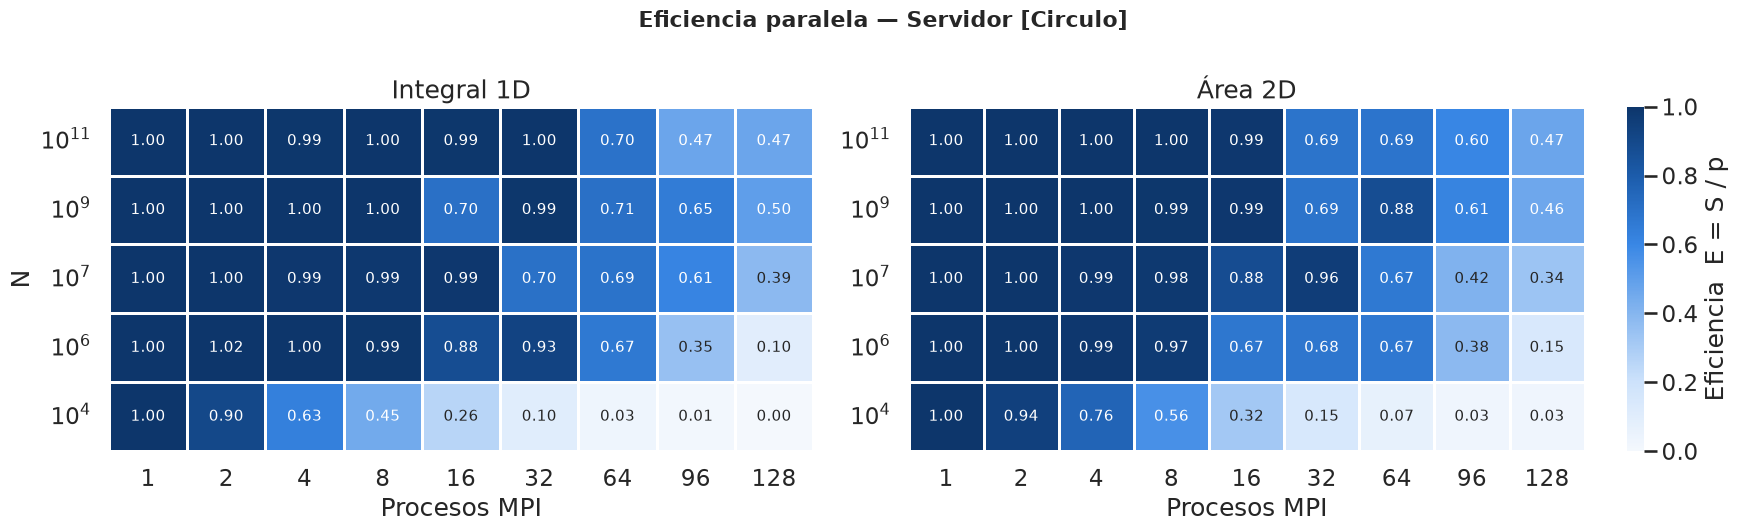

In [6]:
if 'df_resultados' in locals():
    fig, axes = plt.subplots(1, 2, figsize=(18, 5.5), gridspec_kw={'width_ratios': [1, 1.2]})
    for k, (ax, metodo) in enumerate(zip(axes, METODOS)):
        piv = (df_resultados[df_resultados['Método'] == metodo]
               .pivot(index='N', columns='procesos', values='Eficiencia')
               .sort_index(ascending=False))
        piv.index = [etiqueta_N(n) for n in piv.index]
        sns.heatmap(piv, ax=ax, annot=True, fmt='.2f', cmap=CMAP_SEQ, vmin=0, vmax=1,
                    linewidths=2, linecolor=FONDO, cbar=(k == 1),
                    cbar_kws={'label': 'Eficiencia  E = S / p'}, annot_kws={'size': 11})
        ax.set(title=metodo, xlabel='Procesos MPI', ylabel='N' if k == 0 else '')
        ax.tick_params(axis='y', rotation=0)
    fig.suptitle(f'Eficiencia paralela — {ENTORNO.capitalize()} [{FIGURA.capitalize()}]', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

> 🧠 **Análisis:**
> - **Filas:** el tamaño $N$, con el mayor arriba. **Columnas:** el número de procesos. **Color:** más oscuro significa mayor eficiencia; 0.50 quiere decir que la mitad del tiempo de cómputo se pierde.
> 1. **La esquina superior izquierda es oscura:** con $N \ge 10^6$ y $p \le 8$ la eficiencia es ≥ 0.97.
> 2. **Con 64 procesos casi todas las celdas rondan 0.70**, y con 128 la eficiencia baja a ≈ 0.35–0.50 para $N \ge 10^7$ (≈ 0.10–0.15 con $N=10^6$).
> 3. **La caída es escalonada, no gradual.** Hay celdas en 0.99 junto a celdas en 0.70 para el mismo $p$ (por ejemplo, la columna 16 de la Integral 1D: 0.99 con $N=10^{11}$ y 0.70 con $N=10^9$). Si la pérdida viniera de la comunicación, crecería de forma suave con $p$ y bajaría al aumentar $N$. Que no pase así indica que, en algunas corridas, los núcleos procesan más lento: bajada de frecuencia de la CPU (*boost* 3.3 GHz → base 2.25 GHz, una relación de ≈ 1.47 ≈ 1/0.70) o competencia con otros procesos en el servidor compartido. El diagnóstico repetición por repetición está en `analisis_speedup_circulo.ipynb` (sección 6).
> 4. **La fila $10^4$ se aclara enseguida** (≤ 0.76 desde $p=4$ y ≈ 0 con 128 procesos): el problema es demasiado chico para repartirlo.

---
## 6. Comparación de Rendimiento: PC Local vs Servidor HPC

En esta sección comparamos dos equipos con capacidades muy distintas, según la telemetría de `specs_entorno.txt` y `specs_entorno_servidor.txt`:

| Característica | PC Local (Laptop / WSL2) | Servidor HPC |
| :--- | :--- | :--- |
| **Procesador (CPU)** | **AMD Ryzen 5 3450U** with Radeon Vega Mobile | **2 × AMD EPYC 7B12** (dual socket) |
| **Núcleos / Hilos** | **4 núcleos físicos**, 8 hilos (SMT) | **128 núcleos físicos** (sin SMT, 1 hilo por núcleo) |
| **Frecuencia** | base 2.1 GHz, *boost* hasta 3.5 GHz | base 2.25 GHz, *boost* hasta 3.3 GHz |
| **Memoria RAM** | **8 GB** instalados (~5.7 GiB visibles en WSL2) | **503 GiB** (~512 GB) |
| **Memoria Caché L3**| **4 MiB** | **512 MiB** (32 × 16 MiB) |
| **Topología NUMA**   | 1 nodo | 2 nodos (cores 0–63 y 64–127) |
| **Procesos MPI medidos**| 1, 2, 4, 6 (con 6 hay más procesos que núcleos físicos: se usa SMT) | 1, 2, 4, 8, 16, 32, 64, 96, 128 |

> **Nota.** Ambos programas usan memoria $O(1)$: no guardan arreglos, solo un acumulador y el estado de `drand48`. El cálculo está **limitado por la CPU**, así que la RAM no influye en los tiempos.

Speedup y eficiencia se calculan respecto del $T_1$ **de cada equipo**. Evaluamos:
1. **Speedup y eficiencia en el rango común (6.1):** hasta 8 procesos, donde hay datos de los dos equipos.
2. **Eficiencia en todo el rango (6.2):** la PC hasta 6 procesos y el Servidor hasta 128.
3. **Conclusiones** sobre los límites de cada equipo.

In [7]:
# Carga y consolidación de datos: PC Local vs Servidor HPC
import os

archivo_int_pc = f"integral_{FIGURA}_pc.csv"
archivo_area_pc = f"area_{FIGURA}_pc.csv"

archivo_int_srv = f"integral_{FIGURA}_servidor.csv"
archivo_area_srv = f"area_{FIGURA}_servidor.csv"

dfs_comparacion = []

# Carga datos de PC Local (Ryzen 5 3450U: 4 cores físicos, 8 hilos SMT)
if os.path.exists(archivo_int_pc):
    d_int_pc = pd.read_csv(archivo_int_pc).groupby(["N", "procesos"])[["tiempo_segundos", "valor_estimado"]].median().reset_index()
    d_int_pc["Método"] = "Integral 1D"
    d_int_pc["Entorno"] = "PC (Ryzen 5 3450U, 4C/8T)"
    dfs_comparacion.append(d_int_pc)

if os.path.exists(archivo_area_pc):
    d_area_pc = pd.read_csv(archivo_area_pc).groupby(["N", "procesos"])[["tiempo_segundos", "valor_estimado"]].median().reset_index()
    d_area_pc["Método"] = "Área 2D"
    d_area_pc["Entorno"] = "PC (Ryzen 5 3450U, 4C/8T)"
    dfs_comparacion.append(d_area_pc)

# Carga datos de Servidor HPC (Dual EPYC 7B12: 128 cores físicos, 512 GB RAM)
if os.path.exists(archivo_int_srv):
    d_int_srv = pd.read_csv(archivo_int_srv).groupby(["N", "procesos"])[["tiempo_segundos", "valor_estimado"]].median().reset_index()
    d_int_srv["Método"] = "Integral 1D"
    d_int_srv["Entorno"] = "Servidor (EPYC 7B12, 128C)"
    dfs_comparacion.append(d_int_srv)

if os.path.exists(archivo_area_srv):
    d_area_srv = pd.read_csv(archivo_area_srv).groupby(["N", "procesos"])[["tiempo_segundos", "valor_estimado"]].median().reset_index()
    d_area_srv["Método"] = "Área 2D"
    d_area_srv["Entorno"] = "Servidor (EPYC 7B12, 128C)"
    dfs_comparacion.append(d_area_srv)

if dfs_comparacion:
    df_hw = pd.concat(dfs_comparacion, ignore_index=True)
    
    # Speedup y Eficiencia calculados respecto al T1 del propio entorno y método
    t1_hw = df_hw[df_hw["procesos"] == 1].set_index(["Entorno", "Método", "N"])["tiempo_segundos"]
    df_hw["T1"] = df_hw.set_index(["Entorno", "Método", "N"]).index.map(t1_hw)
    df_hw["Speedup"] = df_hw["T1"] / df_hw["tiempo_segundos"]
    df_hw["Eficiencia"] = df_hw["Speedup"] / df_hw["procesos"]
    df_hw["N_cat"] = df_hw["N"].apply(lambda x: f"10^{int(np.log10(x))}")
    
    print("✅ Datos de PC y Servidor consolidados exitosamente.")
    display(df_hw.groupby(["Entorno", "Método"])[["procesos", "tiempo_segundos"]].agg({"procesos": "max", "tiempo_segundos": ["min", "max"]}))
else:
    print("⚠️ No se encontraron archivos CSV. Asegúrate de ejecutar los scripts primero.")


✅ Datos de PC y Servidor consolidados exitosamente.


procesos tiempo_segundos             
                                            max             min          max
Entorno                    Método                                           
PC (Ryzen 5 3450U, 4C/8T)  Integral 1D        6        0.000102    15.563100
                           Área 2D            6        0.000148    26.544301
Servidor (EPYC 7B12, 128C) Integral 1D      128        0.000034  1372.921450
                           Área 2D          128        0.000045  2239.329538

### 6.1 Speedup y eficiencia en el rango común (hasta 8 procesos)
La comparación se hace solo **hasta 8 procesos**, porque la PC llega a 6 y más allá no hay datos de los dos equipos. Se usan los dos tamaños grandes que comparten ambos entornos ($10^7$ y $10^9$).

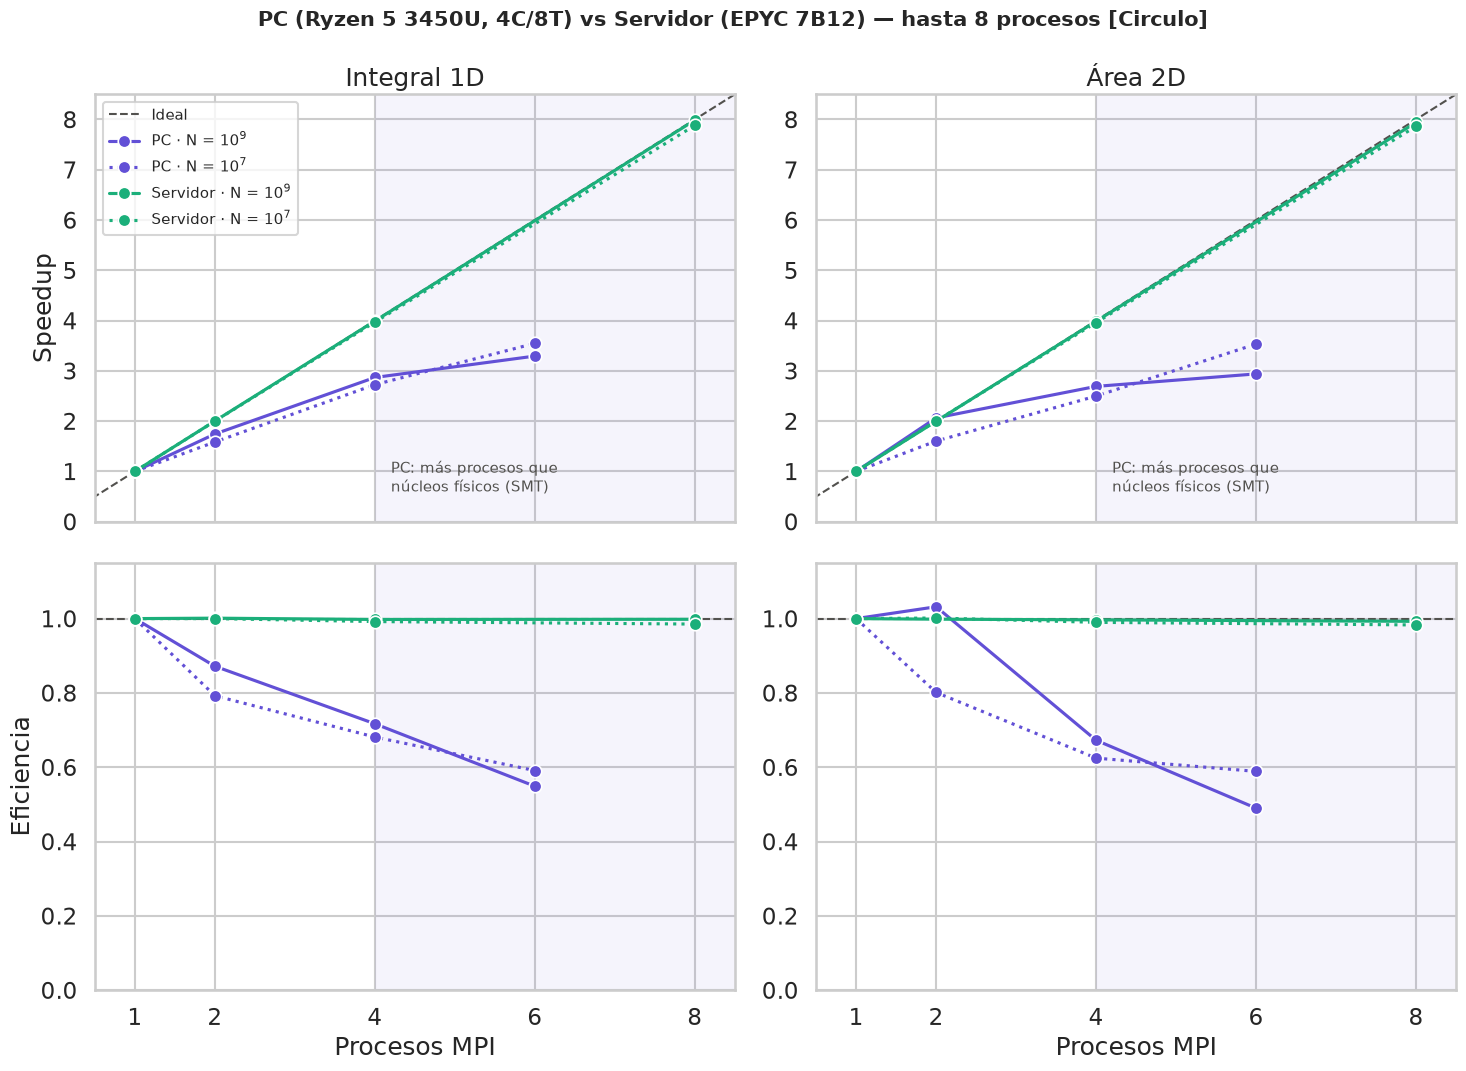

In [8]:
if 'df_hw' in locals() and not df_hw.empty:
    cmp_ = df_hw[df_hw['N'].isin([10**7, 10**9]) & (df_hw['procesos'] <= 8)].copy()
    cmp_['Entorno'] = cmp_['Entorno'].str.split().str[0]   # 'PC' / 'Servidor'
    ESTILO_N = {10**9: '-', 10**7: ':'}

    fig, axes = plt.subplots(2, 2, figsize=(15, 11), sharex=True)
    for col, metodo in enumerate(METODOS):
        ax_s, ax_e = axes[0, col], axes[1, col]
        ax_s.plot([0, 8.5], [0, 8.5], color=TINTA_2, ls='--', lw=1.5, label='Ideal')
        ax_e.axhline(1, color=TINTA_2, ls='--', lw=1.5, label='Ideal')
        for ax in (ax_s, ax_e):
            ax.axvspan(4, 8.5, color=COLOR_ENTORNO['PC'], alpha=0.06, lw=0)
        ax_s.text(4.2, 0.6, 'PC: más procesos que\nnúcleos físicos (SMT)', fontsize=11, color=TINTA_2)
        for entorno in ENTORNOS:
            for n, ls in ESTILO_N.items():
                s = cmp_[(cmp_['Entorno'] == entorno) & (cmp_['Método'] == metodo) & (cmp_['N'] == n)].sort_values('procesos')
                kw = dict(color=COLOR_ENTORNO[entorno], ls=ls, marker='o', mec=FONDO, mew=1.2,
                          label=f'{entorno} · N = {etiqueta_N(n)}')
                ax_s.plot(s['procesos'], s['Speedup'], **kw)
                ax_e.plot(s['procesos'], s['Eficiencia'], **kw)
        ax_s.set(title=metodo, xlim=(0.5, 8.5), ylim=(0, 8.5), ylabel='Speedup' if col == 0 else '')
        ax_e.set(xlabel='Procesos MPI', ylim=(0, 1.15), ylabel='Eficiencia' if col == 0 else '')
        ax_e.set_xticks([1, 2, 4, 6, 8])
    axes[0, 0].legend(loc='upper left', fontsize=11)
    fig.suptitle(f'PC (Ryzen 5 3450U, 4C/8T) vs Servidor (EPYC 7B12) — hasta 8 procesos [{FIGURA.capitalize()}]',
                 fontsize=15, fontweight='bold')
    plt.tight_layout()
    plt.show()

> 🧠 **Análisis:**
> - **Fila superior:** speedup; **fila inferior:** eficiencia. **Columnas:** un método cada una. **Color:** el entorno. **Trazo:** el tamaño $N$ (continuo $10^9$, punteado $10^7$). **Zona sombreada:** el rango en que la PC usa más procesos que núcleos físicos.
> 1. **El Servidor sigue la diagonal hasta 8 procesos** (eficiencia ≈ 1.0): cada proceso tiene un núcleo físico propio.
> 2. **La PC pierde eficiencia antes:**
>    - Con 2 procesos suele caer a ≈ 0.8–0.9 (salvo el Área 2D con $N=10^9$, que llega a 1.0), y con 4 a ≈ 0.6–0.7, aunque todavía hay un núcleo por proceso.
>    - La causa más probable es la **frecuencia**: un procesador de notebook (serie U, 15 W) mantiene 3.5 GHz con un núcleo activo pero baja bastante con los 4 activos, por límites de potencia y temperatura.
> 3. **Con 6 procesos la PC llega a $S \approx 2.9$–$3.5$** (eficiencia ≈ 0.5–0.6): apenas por encima de lo que logra con 4. Los procesos 5 y 6 comparten núcleo físico con otros mediante SMT y aportan poco en un cálculo que usa al máximo las unidades de punto flotante.

### 7. Concluciones

> 🧠 **Conclusiones de la comparación:**
>
> 1. **PC: el límite son los 4 núcleos físicos y la potencia de la notebook.**
>    - Con 4 procesos el speedup es ≈ 2.5–2.9× (eficiencia ≈ 0.62–0.72) para $N \ge 10^7$, aunque hay un núcleo por proceso: la CPU baja su frecuencia cuando trabajan todos los núcleos.
>    - Con 6 procesos llega a ≈ 2.9–3.5× (eficiencia ≈ 0.5–0.6). Los procesos extra comparten núcleo mediante SMT y compiten por las mismas unidades de punto flotante. **SMT casi no aumenta la capacidad de cálculo en Monte Carlo.**
>
> 2. **Servidor: escala casi perfecto hasta 8 procesos y se estabiliza en ≈ 60× con 128.**
>    - Hasta 8 procesos la eficiencia es ≈ 0.97–1.0 para $N \ge 10^6$.
>    - Desde 16–32 procesos aparecen caídas escalonadas a ≈ 0.70, y con 128 la eficiencia queda en ≈ 0.35–0.50. Como la comunicación es mínima (un `MPI_Reduce` de 8 bytes), la pérdida viene de que cada núcleo procesa más lento: bajada de frecuencia y uso compartido del servidor.
>
> 3. **La memoria no influye.** Ambos programas usan memoria $O(1)$, así que la diferencia de RAM (5.7 GiB frente a 503 GiB) no afecta los tiempos. La PC también podría correr $N=10^{11}$; simplemente tardaría ≈ 25–45 minutos con 1 proceso.
>
> 4. **Strong scaling y ley de Amdahl.** Con $N$ fijo, al aumentar $p$ cada proceso hace $N/p$ muestras. Para $N = 10^4$ el costo de arrancar y coordinar los procesos MPI supera al cálculo: el speedup no pasa de ≈ 4–5× y, con 128 procesos en la Integral 1D, cae a $S = 0.25$. Para $N \ge 10^7$ el cómputo domina y el Servidor alcanza ≈ 43–64× con 128 procesos.
>
> 5. **Integral 1D vs Área 2D.** Los dos métodos escalan de forma parecida porque se paralelizan igual (reparto estático de muestras y un único `MPI_Reduce`). La diferencia está en el costo y la precisión por muestra:
>    - La Integral 1D (1 `drand48()` + 1 `sqrt()`) tarda ≈ 14 ns por muestra en el Servidor, frente a ≈ 22 ns del Área 2D (2 `drand48()` + 1 comparación).
>    - Además tiene menor varianza ($\sigma \approx 0.89$ frente a $1.64$). Por eso, para un mismo error, la Integral 1D es la opción más barata.
>
> 6. **Tiempo absoluto.** Con 1 proceso la PC y el Servidor rinden parecido (≈ 1.1–1.2× a favor del Servidor). La ventaja del Servidor viene de la cantidad de núcleos: con su mejor configuración resuelve $N=10^9$ ≈ 22–24 veces más rápido que la PC.